# Grafo de metro de Paris

Estaciones: 43
Tramos: 69


Text(0.5, 1.0, 'Metro de Paris')

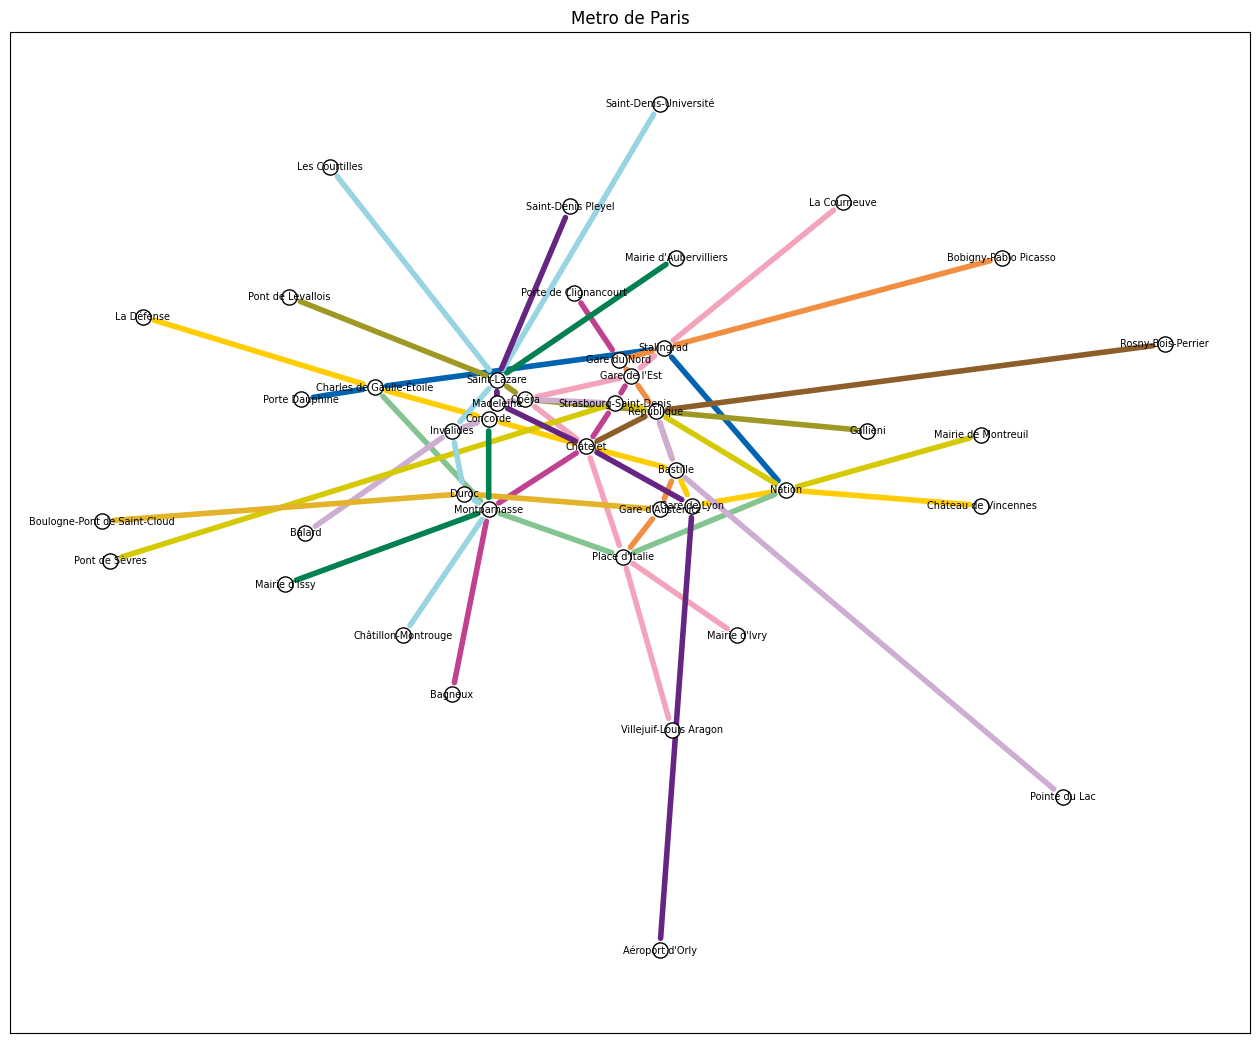

In [13]:
import networkx as nx
import matplotlib.pyplot as plt

# Lineas: color, estación inicial... estación final])
lineas = {
    "Línea 1": ("#FFCD00", ["La Défense", "Charles de Gaulle-Étoile", "Concorde",
                            "Châtelet", "Bastille", "Gare de Lyon", "Nation",
                            "Château de Vincennes"]),
    "Línea 2": ("#0064B0", ["Porte Dauphine", "Charles de Gaulle-Étoile",
                            "Stalingrad", "Nation"]),
    "Línea 3": ("#9F9825", ["Pont de Levallois", "Saint-Lazare", "Opéra",
                            "République", "Gallieni"]),
    "Línea 4": ("#C04191", ["Porte de Clignancourt", "Gare du Nord",
                            "Gare de l'Est", "Strasbourg-Saint-Denis",
                            "Châtelet", "Montparnasse", "Bagneux"]),
    "Línea 5": ("#F28E42", ["Bobigny-Pablo Picasso", "Stalingrad", "Gare du Nord",
                            "Gare de l'Est", "République", "Bastille",
                            "Gare d'Austerlitz", "Place d'Italie"]),
    "Línea 6": ("#83C491", ["Charles de Gaulle-Étoile", "Montparnasse",
                            "Place d'Italie", "Nation"]),
    "Línea 7": ("#F3A4BA", ["La Courneuve", "Stalingrad", "Gare de l'Est", "Opéra",
                            "Châtelet", "Place d'Italie", "Villejuif-Louis Aragon"]),
    "Línea 7 (ramal)": ("#F3A4BA", ["Place d'Italie", "Mairie d'Ivry"]),
    "Línea 8": ("#CEADD2", ["Balard", "Invalides", "Concorde", "Madeleine", "Opéra",
                            "Strasbourg-Saint-Denis", "République", "Bastille",
                            "Pointe du Lac"]),
    "Línea 9": ("#D5C900", ["Pont de Sèvres", "Strasbourg-Saint-Denis",
                            "République", "Nation", "Mairie de Montreuil"]),
    "Línea 10": ("#E3B32A", ["Boulogne-Pont de Saint-Cloud", "Duroc",
                             "Gare d'Austerlitz"]),
    "Línea 11": ("#8D5E2A", ["Rosny-Bois-Perrier", "République", "Châtelet"]),
    "Línea 12": ("#00814F", ["Mairie d'Issy", "Montparnasse", "Concorde",
                             "Madeleine", "Saint-Lazare", "Mairie d'Aubervilliers"]),
    "Línea 13": ("#98D4E2", ["Châtillon-Montrouge", "Montparnasse", "Duroc",
                             "Invalides", "Saint-Lazare", "Saint-Denis-Université"]),
    "Línea 13 (ramal)": ("#98D4E2", ["Saint-Lazare", "Les Courtilles"]),
    "Línea 14": ("#662483", ["Saint-Denis Pleyel", "Saint-Lazare", "Madeleine",
                             "Châtelet", "Gare de Lyon", "Aéroport d'Orly"]),
}

# Posición aproximada de cada estación
posiciones = {
    # Estaciones inicial / final
    "La Défense": (2.238, 48.892),
    "Château de Vincennes": (2.444, 48.844),
    "Porte Dauphine": (2.277, 48.871),
    "Pont de Levallois": (2.274, 48.897),
    "Gallieni": (2.416, 48.863),
    "Porte de Clignancourt": (2.344, 48.898),
    "Bagneux": (2.314, 48.796),
    "Bobigny-Pablo Picasso": (2.449, 48.907),
    "La Courneuve": (2.410, 48.921),
    "Villejuif-Louis Aragon": (2.368, 48.787),
    "Mairie d'Ivry": (2.384, 48.811),
    "Balard": (2.278, 48.837),
    "Pointe du Lac": (2.464, 48.770),
    "Pont de Sèvres": (2.230, 48.830),
    "Mairie de Montreuil": (2.444, 48.862),
    "Boulogne-Pont de Saint-Cloud": (2.228, 48.840),
    "Rosny-Bois-Perrier": (2.489, 48.885),
    "Mairie d'Issy": (2.273, 48.824),
    "Mairie d'Aubervilliers": (2.369, 48.907),
    "Châtillon-Montrouge": (2.302, 48.811),
    "Saint-Denis-Université": (2.365, 48.946),
    "Les Courtilles": (2.284, 48.930),
    "Saint-Denis Pleyel": (2.343, 48.920),
    "Aéroport d'Orly": (2.365, 48.731),
    # Estaciones intermedio
    "Charles de Gaulle-Étoile": (2.295, 48.874),
    "Concorde": (2.323, 48.866),
    "Châtelet": (2.347, 48.859),
    "Bastille": (2.369, 48.853),
    "Gare de Lyon": (2.373, 48.844),
    "Nation": (2.396, 48.848),
    "Stalingrad": (2.366, 48.884),
    "Saint-Lazare": (2.325, 48.876),
    "Opéra": (2.332, 48.871),
    "République": (2.364, 48.868),
    "Gare du Nord": (2.355, 48.881),
    "Gare de l'Est": (2.358, 48.877),
    "Strasbourg-Saint-Denis": (2.354, 48.870),
    "Montparnasse": (2.323, 48.843),
    "Gare d'Austerlitz": (2.365, 48.843),
    "Place d'Italie": (2.356, 48.831),
    "Invalides": (2.314, 48.863),
    "Madeleine": (2.325, 48.870),
    "Duroc": (2.317, 48.847),
}

# Grafo
G = nx.MultiGraph()

# Estaciones
for estacion in posiciones:
    G.add_node(estacion)

# Tramos de cada línea
for nombre in lineas:
    color = lineas[nombre][0]
    estaciones = lineas[nombre][1]
    for i in range(len(estaciones) - 1):
        G.add_edge(estaciones[i], estaciones[i + 1], linea=nombre, color=color)

print("Estaciones:", G.number_of_nodes())
print("Tramos:", G.number_of_edges())

plt.figure(figsize=(16, 13))

for nombre in lineas:
    color = lineas[nombre][0]
    aristas = []
    for u, v, datos in G.edges(data=True):
        if datos["linea"] == nombre:
            aristas.append((u, v))
    nx.draw_networkx_edges(G, posiciones, edgelist=aristas,
                           edge_color=color, width=4)

nx.draw_networkx_nodes(G, posiciones, node_size=120, node_color="white",
                       edgecolors="black")
nx.draw_networkx_labels(G, posiciones, font_size=7)

# Leyenda con los nombres de las líneas
for nombre in lineas:
    if "ramal" not in nombre:
        plt.plot([], [], color=lineas[nombre][0], linewidth=4, label=nombre)

plt.title("Metro de Paris")